In [1]:
import importlib.util
import subprocess
import sys
for module, package in [('numpy','numpy'),('pandas','pandas'),('matplotlib','matplotlib'),('sklearn','scikit-learn')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import base64
import gc
import json
import random
import shutil
import time
import traceback
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.models import vgg16, alexnet, VGG16_Weights, AlexNet_Weights
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import nms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from IPython.display import display
FAST_MODE = True
SEED = 42
ROOT = Path.cwd()/('Lab2_results_fast' if FAST_MODE else 'Lab2_results_full')/('run_'+str(time.time_ns()))
ROOT.mkdir(parents=True,exist_ok=True)
DATA_DIR = Path.cwd()/'data'
Q1_SPLIT_FILE = Path.cwd()/'results_q1'/'split_indices.npz'
CLASS_TRAIN_LIMIT = 6000 if FAST_MODE else None
DETECTION_TRAIN_LIMIT = 2000 if FAST_MODE else None
CLASS_EPOCHS = 2 if FAST_MODE else 5
VIT_EPOCHS = 3 if FAST_MODE else 10
DET_EPOCHS = 2 if FAST_MODE else 5
SCORE_THRESHOLD = 0.5
DET_SIZE = 64
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
if DEVICE.type!='cuda': raise RuntimeError('Activer un GPU Colab avant Tout executer.')
try:
    assert nms(torch.tensor([[0.,0.,2.,2.]],device=DEVICE),torch.tensor([0.9],device=DEVICE),0.5).numel()==1
except Exception as exc:
    raise RuntimeError('NMS CUDA indisponible : utiliser une paire torch/torchvision compatible du runtime Colab.') from exc
ENV={'torch':torch.__version__,'torchvision':torchvision.__version__,'numpy':np.__version__,
     'python':sys.version,'gpu':torch.cuda.get_device_name(0),'fast_mode':FAST_MODE,'seed':SEED}
print(ENV)
print('GPU libre / total GiB:',[round(v/2**30,2) for v in torch.cuda.mem_get_info()])
(ROOT/'environment.json').write_text(json.dumps(ENV,indent=2),encoding='utf-8')


{'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.4.6', 'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'gpu': 'Tesla T4', 'fast_mode': True, 'seed': 42}
GPU libre / total GiB: [14.44, 14.56]


204

100%|██████████| 9.91M/9.91M [00:06<00:00, 1.46MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]


{'split_source': 'reconstruction selon code Q1 ; identite historique non verifiee', 'train_pool': 54000, 'train_classification': 6000, 'train_detection': 2000, 'validation': 6000, 'test': 10000, 'classification_mean': 0.13132168352603912, 'classification_std': 0.30885860323905945, 'detection_mean': 0.1315276175737381, 'detection_std': 0.3092520236968994, 'fast_mode': True, 'classification_epochs': 2, 'vit_epochs': 3, 'detection_epochs': 2}


,train_classification,train_detection,validation,test
0,592,197,592,980
1,674,225,674,1135
2,596,199,596,1032
3,613,204,613,1010
4,584,195,584,982
5,542,181,542,892
6,592,197,592,958
7,627,209,627,1028
8,585,195,585,974
9,595,198,595,1009


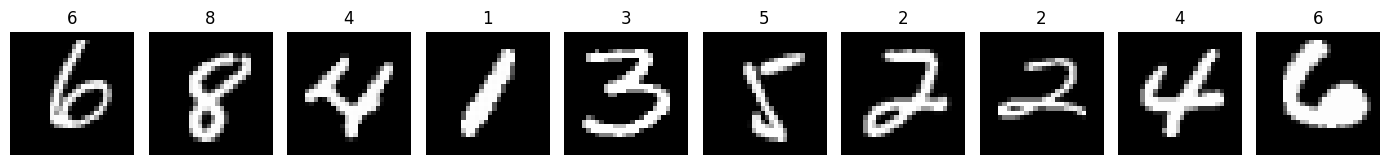

In [2]:
raw_train=datasets.MNIST(DATA_DIR,train=True,download=True)
raw_test=datasets.MNIST(DATA_DIR,train=False,download=True)
y_train=raw_train.targets.numpy()
def validate_split(train,val):
    train,val=np.asarray(train),np.asarray(val)
    for idx in (train,val):
        if idx.ndim!=1 or not np.issubdtype(idx.dtype,np.integer): raise ValueError('Indices 1D entiers requis.')
        if len(np.unique(idx))!=len(idx) or np.any(idx<0) or np.any(idx>=60000): raise ValueError('Indices invalides.')
    if len(train)!=54000 or len(val)!=6000 or np.intersect1d(train,val).size: raise ValueError('Split 54000/6000 disjoint requis.')
    return train.astype(np.int64),val.astype(np.int64)
if Q1_SPLIT_FILE.is_file():
    with np.load(Q1_SPLIT_FILE,allow_pickle=False) as archive:
        tk='train_indices' if 'train_indices' in archive else 'train'
        vk='val_indices' if 'val_indices' in archive else 'validation'
        train_pool,val_idx=validate_split(archive[tk],archive[vk])
    SPLIT_SOURCE='indices Q1 fournis et valides'
else:
    train_pool,val_idx=train_test_split(np.arange(60000),test_size=0.1,random_state=SEED,stratify=y_train)
    train_pool,val_idx=validate_split(train_pool,val_idx)
    SPLIT_SOURCE='reconstruction selon code Q1 ; identite historique non verifiee'
test_idx=np.arange(10000)
def stratified_subset(pool,limit):
    if limit is None or limit==len(pool): return pool.copy()
    chosen,_=train_test_split(pool,train_size=limit,random_state=SEED,stratify=y_train[pool])
    return chosen
class_idx=stratified_subset(train_pool,CLASS_TRAIN_LIMIT)
det_idx=stratified_subset(train_pool,DETECTION_TRAIN_LIMIT)
pixels=raw_train.data[torch.as_tensor(class_idx)].float()/255.
MNIST_MEAN,MNIST_STD=pixels.mean().item(),pixels.std(unbiased=False).item()
del pixels
pixels=raw_train.data[torch.as_tensor(det_idx)].float()/255.
DET_MEAN,DET_STD=pixels.mean().item(),pixels.std(unbiased=False).item()
del pixels
np.savez_compressed(ROOT/'split_indices.npz',train_pool=train_pool,train_classification=class_idx,
                    train_detection=det_idx,validation=val_idx,test=test_idx)
PROTOCOL={'split_source':SPLIT_SOURCE,'train_pool':len(train_pool),'train_classification':len(class_idx),
          'train_detection':len(det_idx),'validation':len(val_idx),'test':len(test_idx),
          'classification_mean':MNIST_MEAN,'classification_std':MNIST_STD,
          'detection_mean':DET_MEAN,'detection_std':DET_STD,'fast_mode':FAST_MODE,
          'classification_epochs':CLASS_EPOCHS,'vit_epochs':VIT_EPOCHS,'detection_epochs':DET_EPOCHS}
(ROOT/'protocol.json').write_text(json.dumps(PROTOCOL,indent=2),encoding='utf-8')
print(PROTOCOL)
counts=pd.DataFrame({'train_classification':np.bincount(y_train[class_idx],minlength=10),
                    'train_detection':np.bincount(y_train[det_idx],minlength=10),
                    'validation':np.bincount(y_train[val_idx],minlength=10),
                    'test':np.bincount(raw_test.targets.numpy(),minlength=10)})
counts.to_csv(ROOT/'class_counts.csv',index_label='digit'); display(counts)
class ClassificationDataset(Dataset):
    def __init__(self,raw,indices,transform): self.raw,self.indices,self.transform=raw,np.asarray(indices),transform
    def __len__(self): return len(self.indices)
    def __getitem__(self,index):
        image,label=self.raw[int(self.indices[index])]
        return self.transform(image),label
small_transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((MNIST_MEAN,),(MNIST_STD,))])
transfer_transform=transforms.Compose([
    transforms.Resize((224,224),interpolation=transforms.InterpolationMode.BILINEAR,antialias=True),
    transforms.Grayscale(num_output_channels=3),transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
def make_class_loaders(transform,batch):
    opts=dict(batch_size=batch,num_workers=0,pin_memory=True)
    return (DataLoader(ClassificationDataset(raw_train,class_idx,transform),shuffle=True,
                       generator=torch.Generator().manual_seed(SEED),**opts),
            DataLoader(ClassificationDataset(raw_train,val_idx,transform),shuffle=False,**opts),
            DataLoader(ClassificationDataset(raw_test,test_idx,transform),shuffle=False,**opts))
fig,axes=plt.subplots(1,10,figsize=(14,2))
for i,ax in enumerate(axes):
    idx=int(class_idx[i]); ax.imshow(raw_train.data[idx],cmap='gray'); ax.set_title(str(y_train[idx])); ax.axis('off')
fig.tight_layout(); fig.savefig(ROOT/'mnist_examples.png',dpi=150); plt.show()


In [3]:
MODEL_NAMES=['CNN','Faster_RCNN','VGG16','AlexNet','ViT']
records={name:{'model':name,'status':'non execute','accuracy':None,'f1_macro':None,
               'loss':None,'loss_kind':None,'training_seconds':None} for name in MODEL_NAMES}
def write_json(path,value):
    Path(path).write_text(json.dumps(value,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
def sync():
    if DEVICE.type=='cuda': torch.cuda.synchronize()
def cleanup():
    gc.collect()
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
def save_table():
    frame=pd.DataFrame([records[name] for name in MODEL_NAMES])
    frame.to_csv(ROOT/'comparison.csv',index=False)
    # Convert NaN to None without coercing numeric columns back to float.
    write_json(ROOT/'comparison.json',frame.astype(object).where(pd.notnull(frame),None).to_dict(orient='records'))
    return frame
def metrics_from_predictions(y,pred):
    return {'accuracy':float(accuracy_score(y,pred)),
            'f1_macro':float(f1_score(y,pred,labels=list(range(10)),average='macro',zero_division=0))}
def save_prediction_artifacts(folder,y,pred,ids,detection=False):
    pd.DataFrame({'image_id':ids,'true':y,'predicted':pred}).to_csv(folder/'predictions.csv',index=False)
    labels=list(range(10))+([-1] if detection else [])
    cm=confusion_matrix(y,pred,labels=labels)[:10,:]
    columns=[str(i) for i in range(10)]+(['aucune'] if detection else [])
    pd.DataFrame(cm,index=range(10),columns=columns).to_csv(folder/'confusion_matrix.csv',index_label='true')
    report=classification_report(y,pred,labels=list(range(10)),digits=4,zero_division=0)
    (folder/'classification_report.txt').write_text(report,encoding='utf-8')
    fig,ax=plt.subplots(figsize=(10,8)); ax.imshow(cm,cmap='Blues',aspect='auto')
    ax.set_xticks(range(len(columns)),columns,rotation=45); ax.set_yticks(range(10),range(10))
    for i in range(10):
        for j in range(len(columns)):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,
                    color='white' if cm[i,j]>cm.max()/2 else 'black')
    ax.set(xlabel='Prediction',ylabel='Vraie classe',title=folder.name+' - test')
    fig.tight_layout(); fig.savefig(folder/'confusion_matrix.png',dpi=150); plt.show()
def save_curves(folder,history):
    h=pd.DataFrame(history); h.to_csv(folder/'history.csv',index=False)
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for ax,metric in zip(axes,['loss','accuracy','f1_macro']):
        for split in ['train','val']:
            key=f'{split}_{metric}'
            if key in h: ax.plot(h['epoch'],h[key],marker='o',label=split)
        ax.set(xlabel='Epoch',ylabel=metric,title=metric); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(folder/'learning_curves.png',dpi=150); plt.show()
def guarded_run(name,function):
    folder=ROOT/('results_q2' if name=='Faster_RCNN' else name.lower())
    folder.mkdir(parents=True,exist_ok=True)
    try:
        cleanup(); seed_all(); torch.cuda.reset_peak_memory_stats()
        result=function(folder)
        result.update(model=name,status='execute',gpu=ENV['gpu'],fast_mode=FAST_MODE,
                      split_source=SPLIT_SOURCE,peak_memory_gib=torch.cuda.max_memory_allocated()/2**30)
        records[name]=result; write_json(folder/'metrics.json',result)
    except Exception as exc:
        records[name]={'model':name,'status':'echec','error':str(exc),'accuracy':None,'f1_macro':None,
                       'loss':None,'loss_kind':None,'training_seconds':None,'fast_mode':FAST_MODE}
        (folder/'error.txt').write_text(traceback.format_exc(),encoding='utf-8')
        write_json(folder/'metrics.json',records[name]); print(name,'- ECHEC:',exc)
    finally:
        cleanup(); save_table()
def trainable_state(model):
    keys={name for name,p in model.named_parameters() if p.requires_grad}
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items() if k in keys}
def amp_context():
    return torch.autocast(device_type='cuda',dtype=torch.float16) if DEVICE.type=='cuda' else nullcontext()
@torch.inference_mode()
def evaluate_classifier(model,loader):
    model.eval(); total=0.; y=[]; pred=[]
    for images,labels in loader:
        images,labels_gpu=images.to(DEVICE),labels.to(DEVICE)
        with amp_context(): logits=model(images)
        loss=nn.functional.cross_entropy(logits.float(),labels_gpu)
        total+=loss.item()*len(labels); y.extend(labels.tolist()); pred.extend(logits.argmax(1).cpu().tolist())
    return {'loss':total/len(y),**metrics_from_predictions(y,pred)},y,pred


In [4]:
def run_classifier(folder,builder,transform,epochs,batch,lr_head,lr_features=None,pretrained=None):
    train_loader,val_loader,test_loader=make_class_loaders(transform,batch)
    model=builder().to(DEVICE); model.eval()
    with torch.inference_mode():
        sample=next(iter(val_loader))[0][:2].to(DEVICE)
        with amp_context(): assert model(sample).shape==(len(sample),10)
    del sample
    head_params,feature_params=[],[]
    for name,param in model.named_parameters():
        if param.requires_grad:
            (feature_params if name.startswith('features.') else head_params).append(param)
    groups=[{'params':head_params,'lr':lr_head}]
    if feature_params: groups.append({'params':feature_params,'lr':lr_features or lr_head})
    optimizer=torch.optim.AdamW(groups,weight_decay=1e-4)
    scaler=torch.amp.GradScaler('cuda')
    best_loss=float('inf'); best=None; best_epoch=None; history=[]; updates_time=0.
    sync(); started=time.perf_counter()
    for epoch in range(1,epochs+1):
        model.train(); total=0.; y=[]; pred=[]
        sync(); update_start=time.perf_counter()
        for images,labels in train_loader:
            images,labels_gpu=images.to(DEVICE),labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with amp_context():
                logits=model(images); loss=nn.functional.cross_entropy(logits,labels_gpu)
            if not torch.isfinite(loss): raise RuntimeError('Loss non finie.')
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total+=loss.item()*len(labels)
            y.extend(labels.tolist()); pred.extend(logits.argmax(1).detach().cpu().tolist())
        sync(); elapsed=time.perf_counter()-update_start; updates_time+=elapsed
        train_values={'loss':total/len(y),**metrics_from_predictions(y,pred)}
        val_values,_,_=evaluate_classifier(model,val_loader)
        if val_values['loss']<best_loss:
            best_loss=val_values['loss']; best_epoch=epoch; best=trainable_state(model)
        history.append({'epoch':epoch,'update_seconds':elapsed,
                        **{f'train_{k}':v for k,v in train_values.items()},
                        **{f'val_{k}':v for k,v in val_values.items()}})
        print(folder.name,epoch,'val:',val_values)
    sync(); training_seconds=time.perf_counter()-started
    model.load_state_dict(best,strict=False)
    test_values,y,pred=evaluate_classifier(model,test_loader)
    save_curves(folder,history); save_prediction_artifacts(folder,y,pred,test_idx.tolist())
    config={'epochs':epochs,'batch_size':batch,'optimizer':'AdamW','lr_head':lr_head,
            'lr_features':lr_features,'weight_decay':1e-4,'pretrained':pretrained,
            'normalization':'ImageNet' if pretrained else [MNIST_MEAN,MNIST_STD],
            'precision':'FP16 autocast and GradScaler','train_images':len(class_idx)}
    torch.save({'state_dict':best,'partial_trainable_only':bool(pretrained),'pretrained':pretrained,
                'config':config,'best_epoch':best_epoch},folder/'best_model.pt')
    result={**test_values,'loss_kind':'cross_entropy_per_image','training_seconds':training_seconds,
            'updates_only_seconds':updates_time,'best_epoch':best_epoch,'train_images':len(class_idx),
            'val_images':len(val_idx),'test_images':len(test_idx),'config':config,
            'timing_scope':'updates + validation + best state CPU copy; setup/test/export excluded'}
    del model,optimizer,scaler,best
    return result
save_table()


,model,status,accuracy,f1_macro,loss,loss_kind,training_seconds
0,CNN,non execute,None,None,None,None,None
1,Faster_RCNN,non execute,None,None,None,None,None
2,VGG16,non execute,None,None,None,None,None
3,AlexNet,non execute,None,None,None,None,None
4,ViT,non execute,None,None,None,None,None


In [5]:
class ClassicCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                                    nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(3136,128),nn.ReLU(),nn.Dropout(0.5),nn.Linear(128,10))
    def forward(self,x): return self.classifier(self.features(x))
# Architecture documentaire seulement : aucun appel d'entrainement du CNN.
records['CNN']={'model':'CNN','status':'execution anterieure','accuracy':0.9920,'f1_macro':0.9919,
 'loss':0.025146,'loss_kind':'cross_entropy_per_image','training_seconds':152.15,'gpu':'Tesla T4',
 'train_images':54000,'val_images':6000,'test_images':10000,'best_epoch':9,'weights_available':False,
 'source':'execution Q1 anterieure de Kenza, mesures arrondies',
 'split_source':'indices historiques non fournis au moment de la preparation',
 'timing_scope':'updates + validation + best state CPU copy'}
cnn_folder=ROOT/'cnn'; cnn_folder.mkdir(parents=True,exist_ok=True)
write_json(cnn_folder/'metrics.json',records['CNN'])


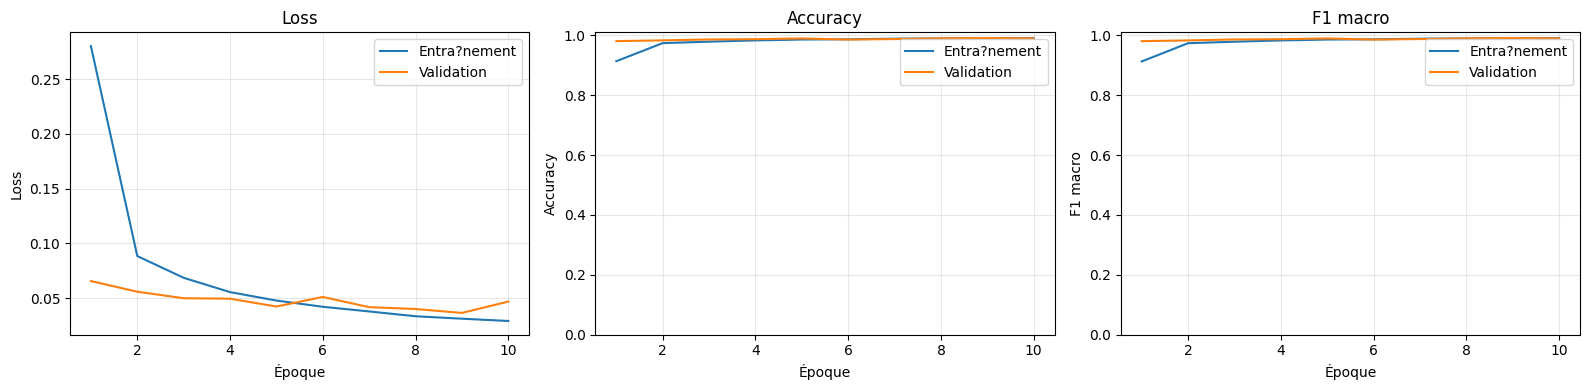

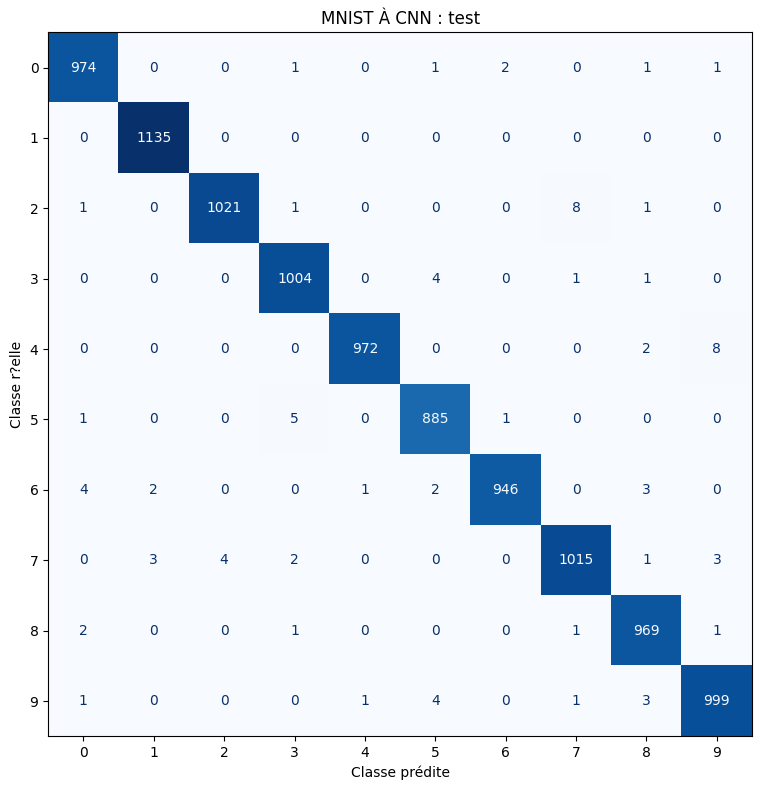

Figures Q1 historiques, aucune nouvelle mesure.


,model,status,accuracy,f1_macro,loss,loss_kind,training_seconds,gpu,train_images,val_images,test_images,best_epoch,weights_available,source,split_source,timing_scope
0,CNN,execution anterieure,0.992,0.9919,0.025146,cross_entropy_per_image,152.15,Tesla T4,54000.0,6000.0,10000.0,9.0,False,"execution Q1 anterieure de Kenza, mesures arro...",indices historiques non fournis au moment de l...,updates + validation + best state CPU copy
1,Faster_RCNN,non execute,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,VGG16,non execute,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AlexNet,non execute,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ViT,non execute,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
CNN_FIGURES = {'learning_curves.png': '...\n', 'confusion_matrix.png': '...\n'}
from IPython.display import Image
for name,encoded in CNN_FIGURES.items():
    data=base64.b64decode(encoded); (cnn_folder/name).write_bytes(data); display(Image(data=data))
print('Figures Q1 historiques, aucune nouvelle mesure.')
save_table()


In [7]:
class DetectionDataset(Dataset):
    def __init__(self,raw,indices): self.raw,self.indices=raw,np.asarray(indices)
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        idx=int(self.indices[i])
        image=self.raw.data[idx].float().unsqueeze(0).repeat(3,1,1)/255.
        return image,{'boxes':torch.tensor([[0.,0.,28.,28.]],dtype=torch.float32),
                      'labels':self.raw.targets[idx].reshape(1).long()+1,
                      'image_id':torch.tensor(idx,dtype=torch.int64)}
def detection_collate(batch): return tuple(map(list,zip(*batch)))
def make_detection_loaders():
    opts=dict(batch_size=2,num_workers=0,collate_fn=detection_collate,pin_memory=True)
    return (DataLoader(DetectionDataset(raw_train,det_idx),shuffle=True,generator=torch.Generator().manual_seed(SEED),**opts),
            DataLoader(DetectionDataset(raw_train,val_idx),shuffle=False,**opts),
            DataLoader(DetectionDataset(raw_test,test_idx),shuffle=False,**opts))
def freeze_bn(model):
    for module in model.modules():
        if isinstance(module,nn.modules.batchnorm._BatchNorm): module.eval()
def build_detector():
    return fasterrcnn_resnet50_fpn(weights=None,weights_backbone=None,num_classes=11,
        min_size=DET_SIZE,max_size=DET_SIZE,image_mean=[DET_MEAN]*3,image_std=[DET_STD]*3,
        rpn_anchor_generator=AnchorGenerator(((8,),(16,),(32,),(64,),(128,)),((0.5,1.,2.),)*5),
        rpn_pre_nms_top_n_train=300 if FAST_MODE else 1000,rpn_pre_nms_top_n_test=300 if FAST_MODE else 1000,
        rpn_post_nms_top_n_train=100 if FAST_MODE else 300,rpn_post_nms_top_n_test=100 if FAST_MODE else 300,
        box_score_thresh=0.,box_detections_per_img=20 if FAST_MODE else 100)
DET_KEYS=['loss_classifier','loss_box_reg','loss_objectness','loss_rpn_box_reg']
def detector_loss_pass(model,loader,optimizer=None):
    modes=[(m,m.training) for m in model.modules()]; total={k:0. for k in DET_KEYS}; n=0
    try:
        model.train(); freeze_bn(model)
        with torch.set_grad_enabled(optimizer is not None):
            for images,targets in loader:
                images=[x.to(DEVICE) for x in images]
                targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
                if optimizer is not None: optimizer.zero_grad(set_to_none=True)
                losses=model(images,targets); loss=sum(losses.values())
                if not torch.isfinite(loss): raise RuntimeError('Detection loss non finie.')
                if optimizer is not None: loss.backward(); optimizer.step()
                for key in total: total[key]+=losses[key].item()*len(images)
                n+=len(images)
    finally:
        for module,mode in modes: module.training=mode
    values={k:v/n for k,v in total.items()}
    return {'loss':sum(values.values()),**values}
def detection_diagnostic(model,loader):
    devices=list(range(torch.cuda.device_count())) if DEVICE.type=='cuda' else []
    with torch.random.fork_rng(devices=devices):
        torch.manual_seed(SEED+123)
        if DEVICE.type=='cuda': torch.cuda.manual_seed_all(SEED+123)
        return detector_loss_pass(model,loader)
def choose_detection(output):
    boxes,scores,labels=output['boxes'],output['scores'],output['labels']
    valid=(torch.isfinite(scores)&(scores>=SCORE_THRESHOLD)&(labels>=1)&(labels<=10)
           &torch.isfinite(boxes).all(1)&(boxes[:,2]>boxes[:,0])&(boxes[:,3]>boxes[:,1]))
    keep=torch.where(valid)[0]
    if len(keep)==0: return -1,0.,None,0
    best=keep[scores[keep].argmax()]
    return int(labels[best].item())-1,float(scores[best].item()),boxes[best].cpu().tolist(),len(keep)
@torch.inference_mode()
def evaluate_detector(model,loader):
    model.eval(); rows=[]
    for images,targets in loader:
        outputs=model([x.to(DEVICE) for x in images])
        for target,output in zip(targets,outputs):
            digit,score,box,count=choose_detection(output)
            rows.append({'image_id':int(target['image_id'].item()),'true':int(target['labels'].item())-1,
                         'predicted':digit,'score':score,'box':box,'valid_detection_count':count})
    frame=pd.DataFrame(rows); metrics=metrics_from_predictions(frame['true'],frame['predicted'])
    metrics.update(no_detection_count=int((frame['predicted']==-1).sum()),
                   no_detection_rate=float((frame['predicted']==-1).mean()),
                   multiple_detection_count=int((frame['valid_detection_count']>1).sum()))
    return metrics,frame


Memoire GPU libre avant detection (GiB): 14.44512939453125
Faster_RCNN 1 validation: {'accuracy': 0.0, 'f1_macro': 0.0, 'no_detection_count': 6000, 'no_detection_rate': 1.0, 'multiple_detection_count': 0}
Faster_RCNN 2 validation: {'accuracy': 0.18566666666666667, 'f1_macro': 0.1742561798715552, 'no_detection_count': 4620, 'no_detection_rate': 0.77, 'multiple_detection_count': 0}


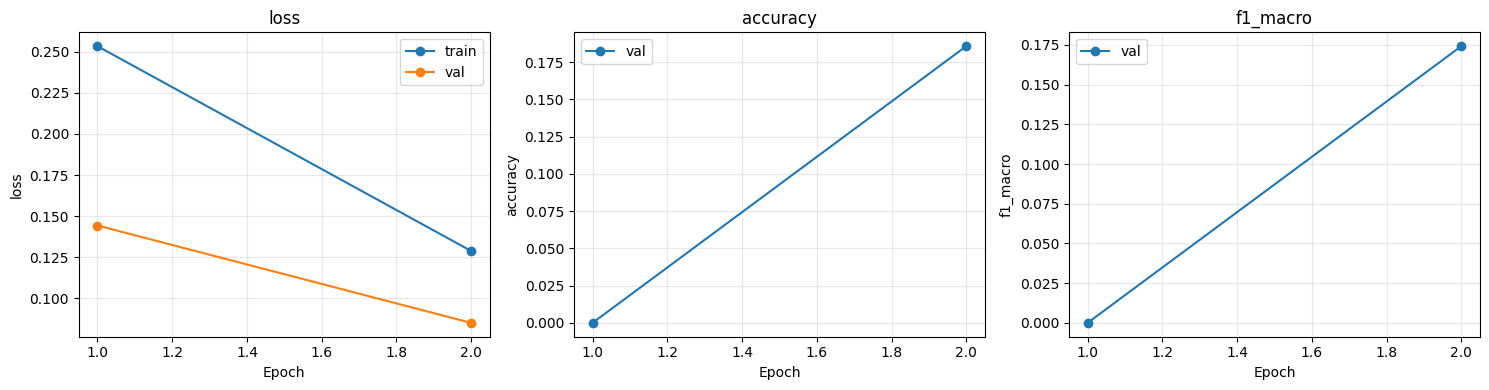

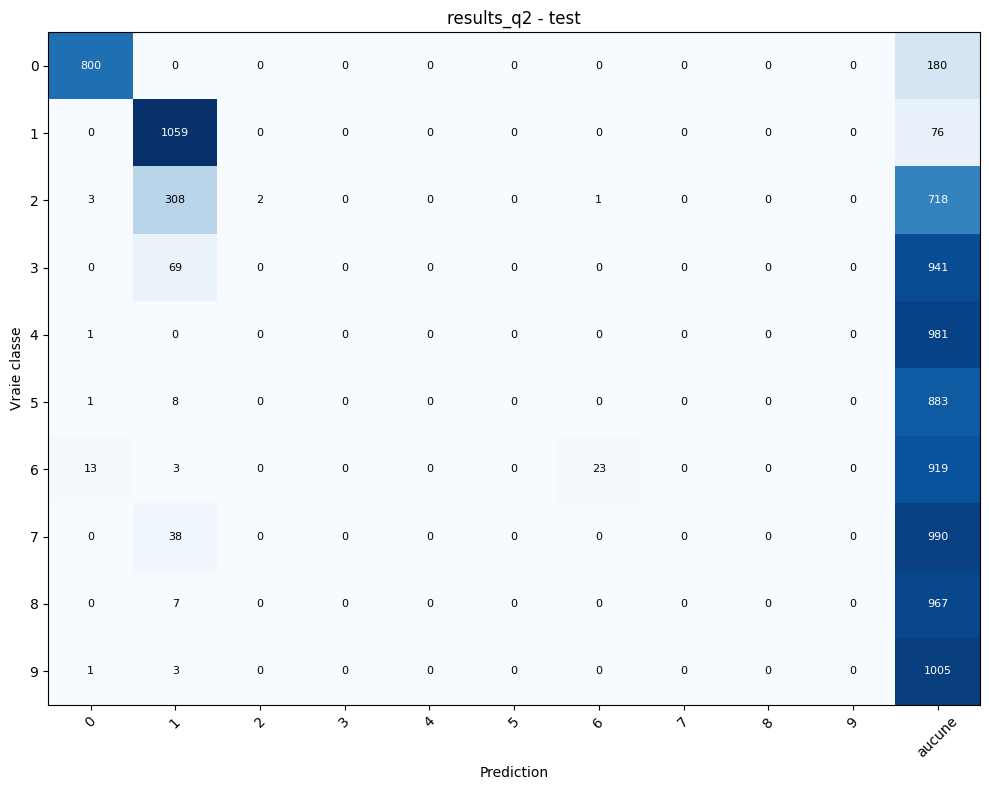

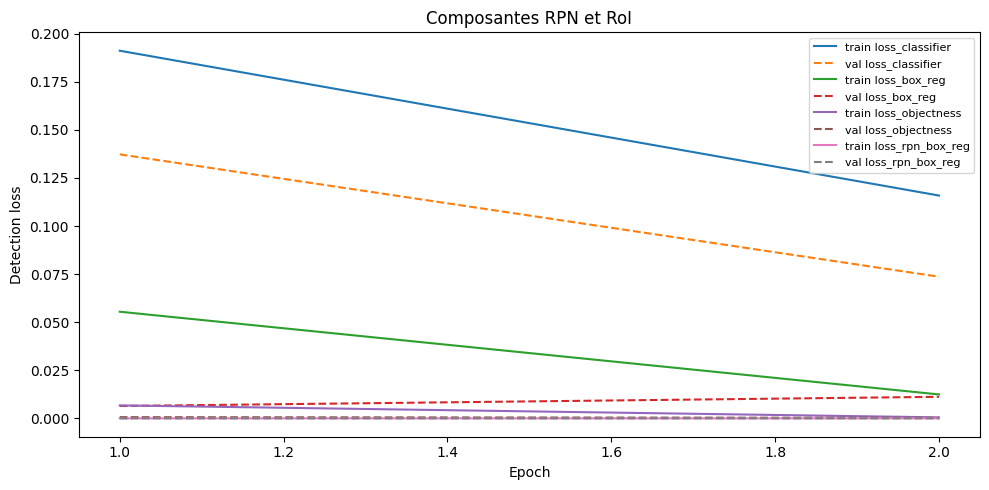

In [8]:
def run_detector(folder):
    free,total=torch.cuda.mem_get_info()
    if free<2*2**30: raise RuntimeError('Moins de 2 GiB GPU libres avant detection.')
    print('Memoire GPU libre avant detection (GiB):',free/2**30)
    train_loader,val_loader,test_loader=make_detection_loaders()
    model=build_detector().to(DEVICE)
    sample_images,sample_targets=next(iter(val_loader))
    assert sample_images[0].shape==(3,28,28) and sample_targets[0]['boxes'].shape==(1,4)
    model.eval()
    with torch.no_grad():
        transformed,_=model.transform([x.to(DEVICE) for x in sample_images],
            [{k:v.to(DEVICE) for k,v in t.items()} for t in sample_targets])
        assert all(size==(64,64) for size in transformed.image_sizes)
        assert len(model([x.to(DEVICE) for x in sample_images]))==len(sample_images)
    detection_diagnostic(model,[(sample_images,sample_targets)])
    del transformed,sample_images,sample_targets
    optimizer=torch.optim.SGD(model.parameters(),lr=0.005,momentum=0.9,weight_decay=0.0005)
    best=None; best_key=(-1.,-1.); best_epoch=None; history=[]; updates_time=0.
    sync(); started=time.perf_counter()
    for epoch in range(1,DET_EPOCHS+1):
        sync(); update_start=time.perf_counter()
        train_losses=detector_loss_pass(model,train_loader,optimizer)
        sync(); update_time=time.perf_counter()-update_start; updates_time+=update_time
        val_losses=detection_diagnostic(model,val_loader)
        val_metrics,_=evaluate_detector(model,val_loader)
        key=(val_metrics['f1_macro'],val_metrics['accuracy'])
        if key>best_key:
            best_key=key; best_epoch=epoch
            best={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        history.append({'epoch':epoch,'update_seconds':update_time,
            **{f'train_{k}':v for k,v in train_losses.items()},
            **{f'val_{k}':v for k,v in {**val_losses,**val_metrics}.items()}})
        print('Faster_RCNN',epoch,'validation:',val_metrics)
    sync(); training_seconds=time.perf_counter()-started
    model.load_state_dict(best)
    test_losses=detection_diagnostic(model,test_loader)
    test_metrics,frame=evaluate_detector(model,test_loader)
    save_curves(folder,history)  # Accuracy/F1 validation seulement ; train non mesure.
    save_prediction_artifacts(folder,frame['true'].tolist(),frame['predicted'].tolist(),
                              frame['image_id'].tolist(),detection=True)
    frame.to_csv(folder/'detection_details.csv',index=False)
    h=pd.DataFrame(history); fig,ax=plt.subplots(figsize=(10,5))
    for key in DET_KEYS:
        ax.plot(h['epoch'],h['train_'+key],label='train '+key)
        ax.plot(h['epoch'],h['val_'+key],ls='--',label='val '+key)
    ax.set(xlabel='Epoch',ylabel='Detection loss',title='Composantes RPN et RoI'); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(folder/'loss_components.png',dpi=150); plt.show()
    config={'epochs':DET_EPOCHS,'batch':2,'lr':0.005,'momentum':0.9,'weight_decay':0.0005,
            'internal_size':DET_SIZE,'threshold':SCORE_THRESHOLD,'weights':None,'weights_backbone':None,
            'anchor_sizes':[8,16,32,64,128],'anchor_ratios':[0.5,1.,2.],
            'normalization':[DET_MEAN,DET_STD],'batchnorm':'initial running stats fixed; affine trainable',
            'proposal_pre_nms':300 if FAST_MODE else 1000,'proposal_post_nms':100 if FAST_MODE else 300,
            'detections_per_image':20 if FAST_MODE else 100}
    torch.save({'state_dict':best,'config':config,'best_epoch':best_epoch},folder/'best_model.pt')
    result={**test_metrics,**test_losses,'loss_kind':'diagnostic_detection_sum_RPN_RoI',
            'training_seconds':training_seconds,'updates_only_seconds':updates_time,
            'train_images':len(det_idx),'val_images':len(val_idx),'test_images':len(test_idx),
            'best_epoch':best_epoch,'config':config,
            'timing_scope':'updates + val diagnostic loss + val inference + best-state copy; setup/test/export excluded'}
    del model,optimizer,best
    return result

guarded_run('Faster_RCNN',run_detector)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 74.0MB/s]


vgg16 1 val: {'loss': 0.1743126762782534, 'accuracy': 0.9506666666666667, 'f1_macro': 0.9504710585389027}
vgg16 2 val: {'loss': 0.08922947480467458, 'accuracy': 0.9748333333333333, 'f1_macro': 0.9746304929213376}


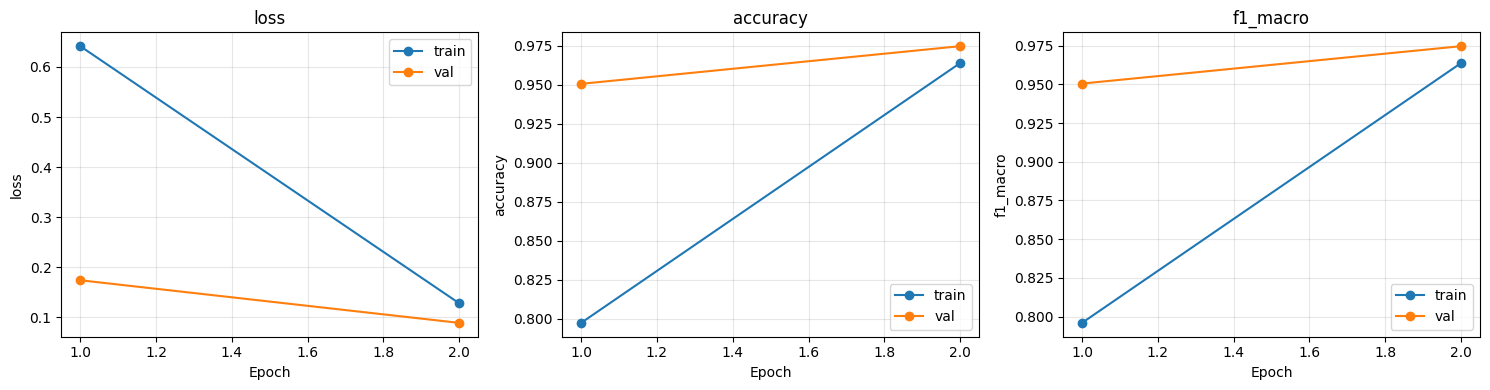

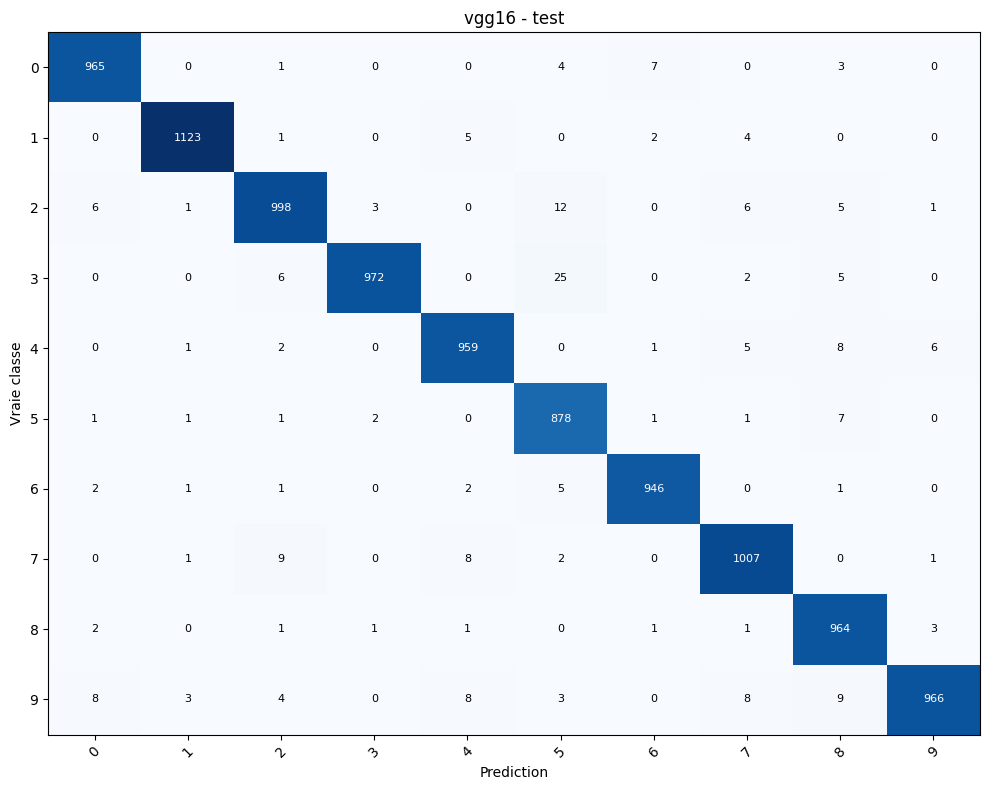

In [9]:
def build_vgg(pretrained=True):
    model=vgg16(weights=VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
    for param in model.parameters(): param.requires_grad=False
    model.avgpool=nn.AdaptiveAvgPool2d((1,1))
    model.classifier=nn.Sequential(nn.Linear(512,128),nn.ReLU(),nn.Dropout(0.3),nn.Linear(128,10))
    for param in model.features[24:].parameters(): param.requires_grad=True
    return model

guarded_run('VGG16',lambda folder:run_classifier(folder,build_vgg,transfer_transform,
    CLASS_EPOCHS,16,1e-3,1e-5,'VGG16_Weights.IMAGENET1K_V1'))


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:05<00:00, 48.8MB/s]


alexnet 1 val: {'loss': 0.3696452820102374, 'accuracy': 0.9055, 'f1_macro': 0.901986952459118}
alexnet 2 val: {'loss': 0.1989013450096051, 'accuracy': 0.9451666666666667, 'f1_macro': 0.9443230496237176}


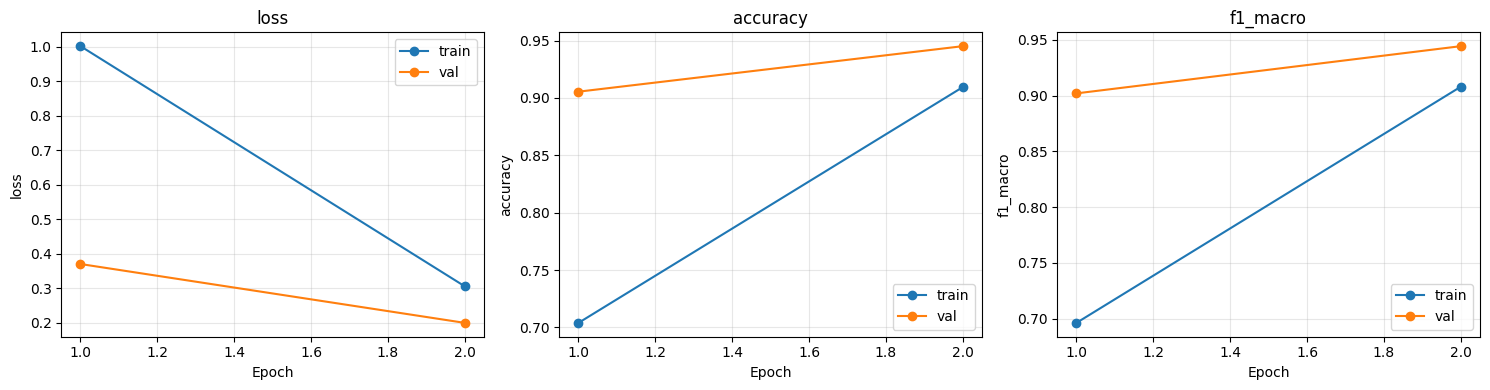

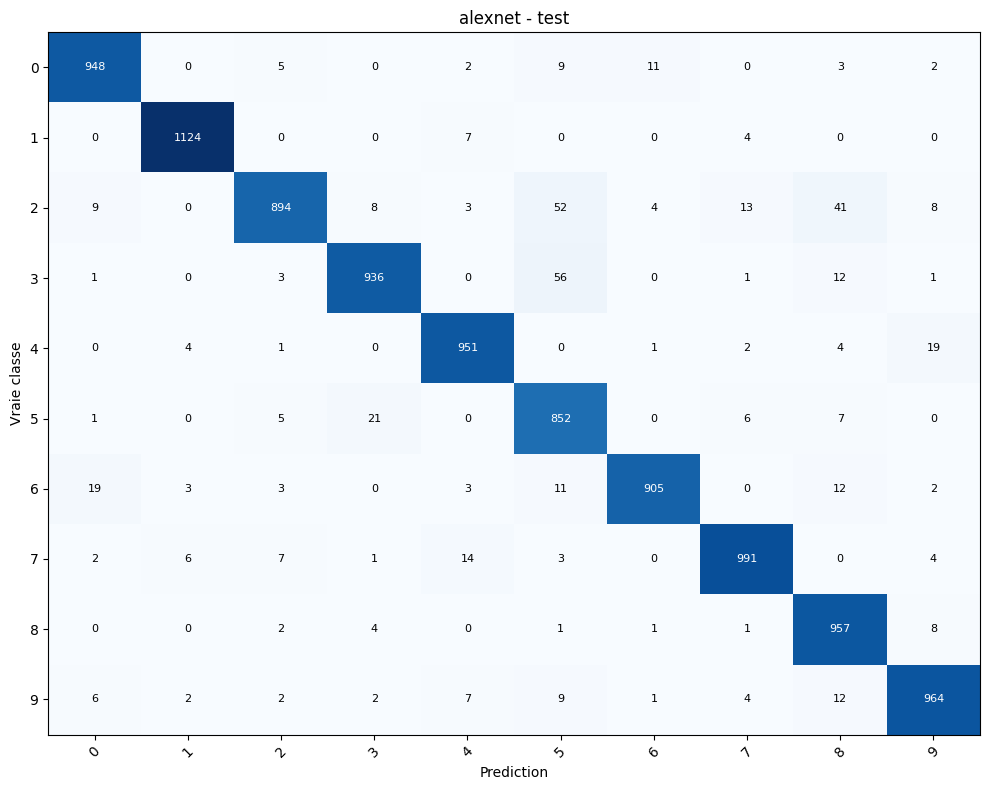

In [10]:
def build_alex(pretrained=True):
    model=alexnet(weights=AlexNet_Weights.IMAGENET1K_V1 if pretrained else None)
    for param in model.parameters(): param.requires_grad=False
    model.avgpool=nn.AdaptiveAvgPool2d((1,1))
    model.classifier=nn.Sequential(nn.Linear(256,128),nn.ReLU(),nn.Dropout(0.3),nn.Linear(128,10))
    for param in model.features[10:].parameters(): param.requires_grad=True
    return model

guarded_run('AlexNet',lambda folder:run_classifier(folder,build_alex,transfer_transform,
    CLASS_EPOCHS,16,1e-3,1e-5,'AlexNet_Weights.IMAGENET1K_V1'))


vit 1 val: {'loss': 1.2497700468699138, 'accuracy': 0.593, 'f1_macro': 0.5715084623899755}
vit 2 val: {'loss': 0.9185820328394572, 'accuracy': 0.6958333333333333, 'f1_macro': 0.6869697672456336}
vit 3 val: {'loss': 0.7462441229820251, 'accuracy': 0.7613333333333333, 'f1_macro': 0.7591675213490179}


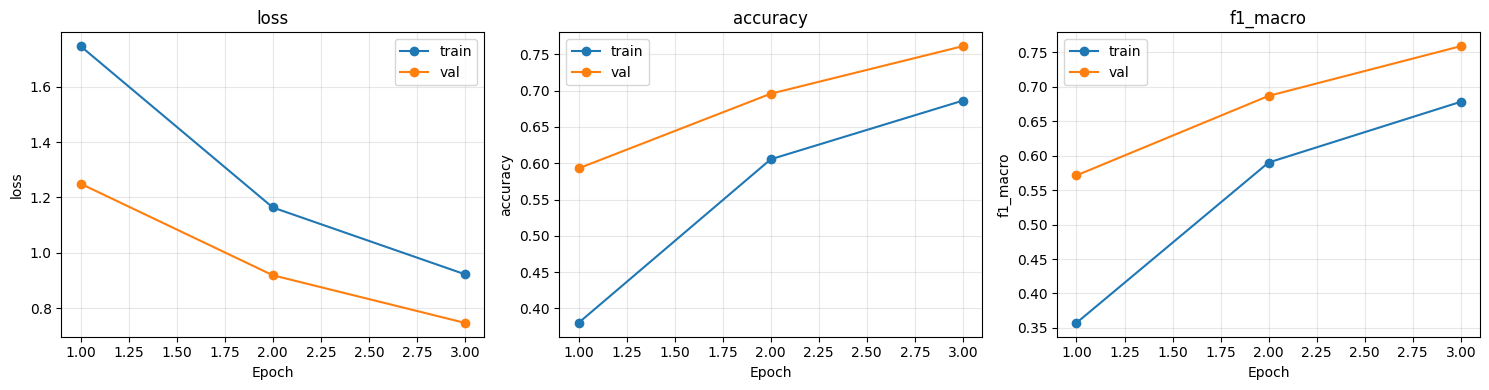

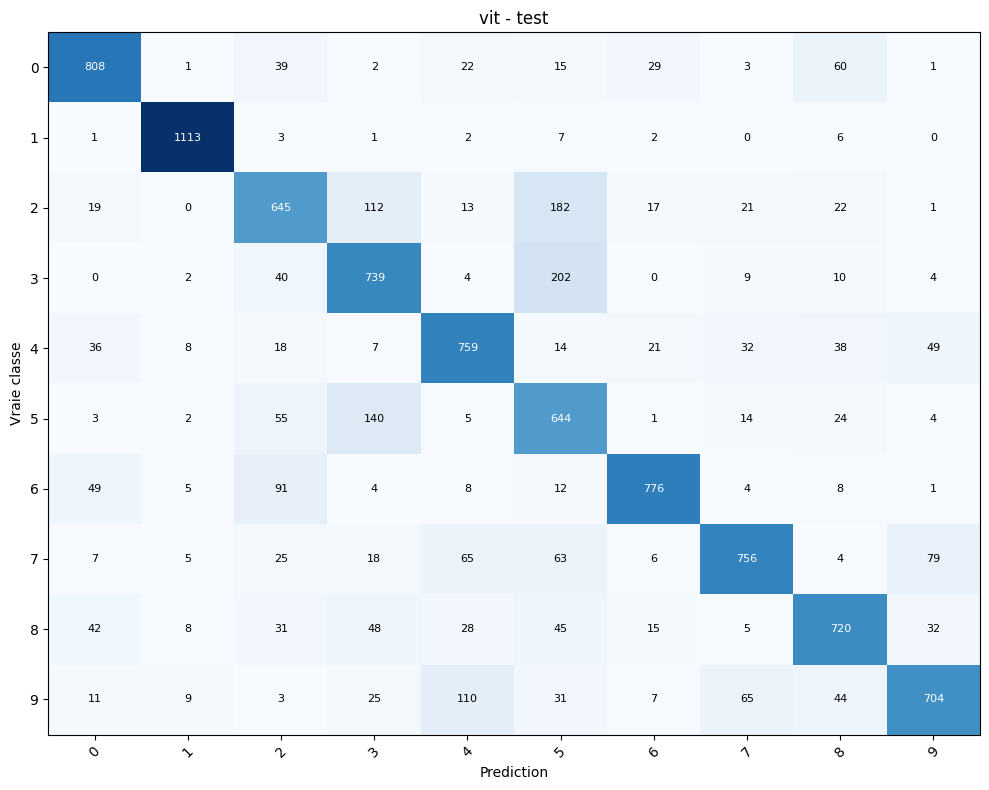

In [11]:
class TransformerBlock(nn.Module):
    def __init__(self,dim=64,heads=4,mlp_dim=128,dropout=0.1):
        super().__init__()
        self.norm1=nn.LayerNorm(dim)
        self.attn=nn.MultiheadAttention(dim,heads,dropout=dropout,batch_first=True)
        self.norm2=nn.LayerNorm(dim)
        self.mlp=nn.Sequential(nn.Linear(dim,mlp_dim),nn.GELU(),nn.Dropout(dropout),
                               nn.Linear(mlp_dim,dim),nn.Dropout(dropout))
        self.dropout=nn.Dropout(dropout)
    def forward(self,x):
        z=self.norm1(x); z,_=self.attn(z,z,z,need_weights=False)
        x=x+self.dropout(z)
        return x+self.mlp(self.norm2(x))
class ScratchViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed=nn.Conv2d(1,64,kernel_size=7,stride=7)
        self.cls_token=nn.Parameter(torch.zeros(1,1,64)); self.position=nn.Parameter(torch.zeros(1,17,64))
        nn.init.trunc_normal_(self.cls_token,std=0.02); nn.init.trunc_normal_(self.position,std=0.02)
        self.dropout=nn.Dropout(0.1)
        self.blocks=nn.Sequential(*[TransformerBlock() for _ in range(4)])
        self.norm=nn.LayerNorm(64); self.head=nn.Linear(64,10)
    def forward(self,x):
        if x.shape[1:]!=(1,28,28): raise ValueError('ViT attend Bx1x28x28.')
        tokens=self.patch_embed(x).flatten(2).transpose(1,2)
        tokens=torch.cat([self.cls_token.expand(x.size(0),-1,-1),tokens],dim=1)
        tokens=self.dropout(tokens+self.position)
        return self.head(self.norm(self.blocks(tokens)[:,0]))

guarded_run('ViT',lambda folder:run_classifier(folder,ScratchViT,small_transform,VIT_EPOCHS,128,1e-3))


,model,status,accuracy,f1_macro,loss,loss_kind,training_seconds,train_images
0,CNN,execution anterieure,0.9920,0.991900,0.025146,cross_entropy_per_image,152.150000,54000
1,Faster_RCNN,execute,0.1884,0.174542,0.084581,diagnostic_detection_sum_RPN_RoI,365.175683,2000
2,VGG16,execute,0.9778,0.977565,0.073748,cross_entropy_per_image,101.877408,6000
3,AlexNet,execute,0.9522,0.951401,0.179173,cross_entropy_per_image,45.613356,6000
4,ViT,execute,0.7664,0.765182,0.739243,cross_entropy_per_image,10.050765,6000


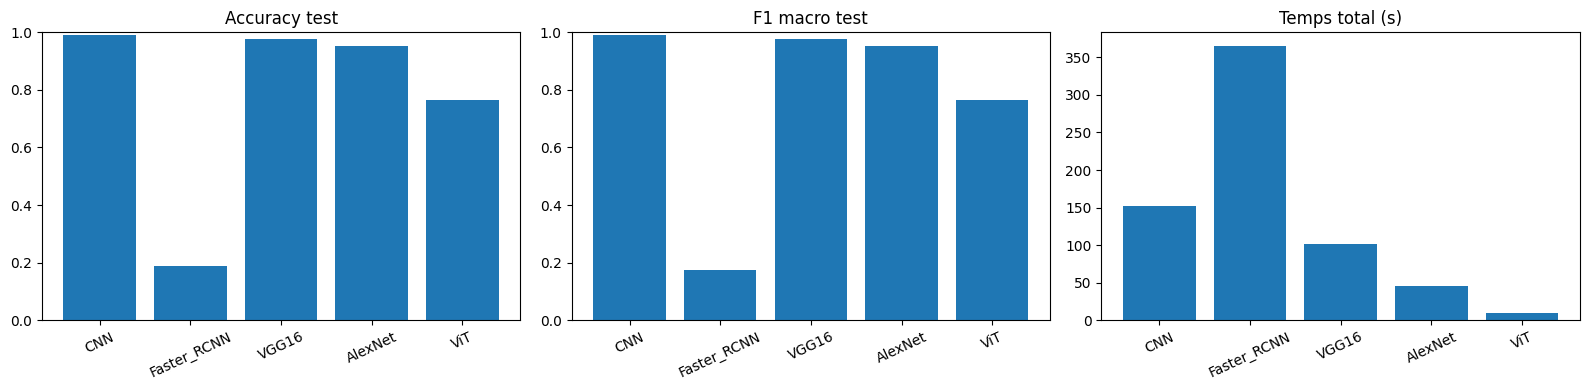

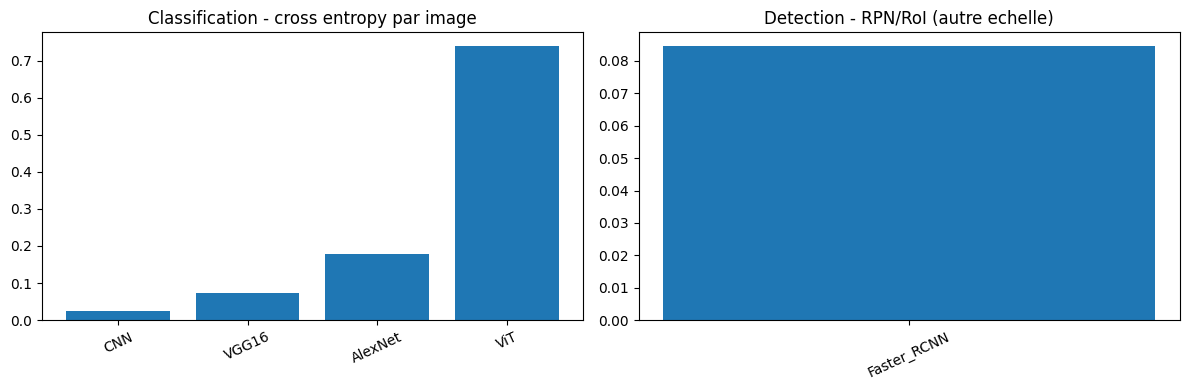

In [12]:
comparison=save_table()
columns=['model','status','accuracy','f1_macro','loss','loss_kind','training_seconds','train_images']
for column in columns:
    if column not in comparison: comparison[column]=None
display(comparison[columns])
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,metric,title in zip(axes,['accuracy','f1_macro','training_seconds'],['Accuracy test','F1 macro test','Temps total (s)']):
    subset=comparison[comparison[metric].notna()]
    ax.bar(subset['model'],subset[metric]); ax.tick_params(axis='x',rotation=25); ax.set_title(title)
    if metric!='training_seconds': ax.set_ylim(0,1)
fig.tight_layout(); fig.savefig(ROOT/'comparison_scores_time.png',dpi=150); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,kind,title in zip(axes,['cross_entropy_per_image','diagnostic_detection_sum_RPN_RoI'],
                         ['Classification - cross entropy par image','Detection - RPN/RoI (autre echelle)']):
    subset=comparison[(comparison['loss_kind']==kind)&comparison['loss'].notna()]
    if len(subset): ax.bar(subset['model'],subset['loss'])
    else: ax.text(0.5,0.5,'Indisponible',ha='center',transform=ax.transAxes)
    ax.set_title(title); ax.tick_params(axis='x',rotation=25)
fig.tight_layout(); fig.savefig(ROOT/'comparison_losses_separate.png',dpi=150); plt.show()


In [13]:
def markdown_table(frame):
    cols=['model','status','accuracy','f1_macro','loss','loss_kind','training_seconds','train_images']
    lines=['| '+' | '.join(cols)+' |','| '+' | '.join(['---']*len(cols))+' |']
    for _,row in frame.iterrows():
        values=[]
        for key in cols:
            value=row.get(key)
            if value is None or (isinstance(value,float) and np.isnan(value)): text='indisponible'
            elif isinstance(value,(float,np.floating)): text=f'{value:.6f}'
            else: text=str(value)
            values.append(text.replace('|','/').replace('\n',' '))
        lines.append('| '+' | '.join(values)+' |')
    return '\n'.join(lines)

analysis=[]
for name in MODEL_NAMES[1:]:
    record=records[name]
    if record['status']!='execute':
        analysis.append(f"{name} : {record['status']} ; aucune conclusion de performance.")
        continue
    folder=ROOT/('results_q2' if name=='Faster_RCNN' else name.lower())
    history=pd.read_csv(folder/'history.csv')
    analysis.append(f"{name} : accuracy {record['accuracy']:.4f}, F1 macro {record['f1_macro']:.4f}, meilleure epoque {record['best_epoch']}.")
    if history.iloc[-1]['val_loss']>history['val_loss'].min():
        analysis.append(f"{name} : la derniere loss de validation depasse son minimum ; surveiller le surapprentissage, sans le conclure sur cette seule observation.")
    matrix=pd.read_csv(folder/'confusion_matrix.csv',index_col=0)
    digits=matrix.iloc[:10,:10].to_numpy().copy(); np.fill_diagonal(digits,0)
    if digits.max()>0:
        i,j=np.unravel_index(digits.argmax(),digits.shape)
        analysis.append(f"{name} : une confusion maximale est {i} vers {j} ({digits[i,j]} images).")
    if name=='Faster_RCNN': analysis.append(f"Absences de detection : {record['no_detection_count']} sur 10000, comptees comme erreurs.")
analysis_text='\n'.join('- '+line for line in analysis)
(ROOT/'analysis.md').write_text(analysis_text,encoding='utf-8')
print(analysis_text)
readme='''# Lab 2 - Deep Learning - Kenza

Notebook unique : `Lab2_DeepLearning_Kenza.ipynb`. Dans Colab, activer le GPU puis lancer Tout executer. MNIST et les poids ImageNet sont telecharges automatiquement. Les originaux ne sont pas modifies.

## Protocole et resultats

CNN : execution anterieure, pas de nouvel entrainement. Les quatre nouveaux modeles utilisent la meme validation de 6000 images et le meme test officiel de 10000 images. FAST_MODE limite seulement les donnees train et les epoques. Les losses de detection et de classification sont de nature differente.

'''+markdown_table(save_table())+'''

Split : '''+SPLIT_SOURCE+'''.
Mode rapide : '''+str(FAST_MODE)+'''. Les budgets ne sont pas identiques a celui du CNN historique ; aucun classement causal des architectures n'est justifie.

VGG16/AlexNet : poids ImageNet, petites tetes et fine-tuning des dernieres convolutions. ViT : patches 7x7, dimension 64, quatre blocs et quatre tetes, sans preentrainement. Faster R-CNN : pseudo-boite sur l'image entiere ; prediction -1 sans detection valide, jamais remplacee par le chiffre 0.

## Analyse de cette execution

'''+analysis_text+'''

## Synthese personnelle

Ce laboratoire m'a appris a construire un protocole autant qu'un reseau. Le CNN fournit deja une reference solide sur MNIST. Un detecteur ajoute une complexite dont cette classification a un seul objet n'a pas naturellement besoin. Le transfert reutilise des filtres existants ; le ViT apprend ses representations depuis zero. Je retiens surtout qu'il faut verifier les donnees, les echecs de detection et le sens de chaque loss avant d'interpreter un tableau de scores.

## Fichiers exportes

`comparison.csv/json`, `protocol.json`, `environment.json`, `split_indices.npz`, figures PNG et sous-dossiers par modele : metriques, historique, predictions et checkpoint. Les figures CNN sont historiques. Les checkpoints VGG16/AlexNet contiennent uniquement les parametres modifies ; reconstruire le modele avec les memes poids ImageNet puis charger avec strict=False. Les checkpoints ViT/Faster R-CNN contiennent tous leurs poids.

Le ZIP est cree en fin de notebook. MNIST et les caches de poids ImageNet sont exclus. Aucun Git ni push.
'''
(ROOT/'README.md').write_text(readme,encoding='utf-8')
(Path.cwd()/'README_Lab2.md').write_text(readme,encoding='utf-8')
print('README genere :',ROOT/'README.md')


- Faster_RCNN : accuracy 0.1884, F1 macro 0.1745, meilleure epoque 2.
- Faster_RCNN : une confusion maximale est 2 vers 1 (308 images).
- Absences de detection : 7660 sur 10000, comptees comme erreurs.
- VGG16 : accuracy 0.9778, F1 macro 0.9776, meilleure epoque 2.
- VGG16 : une confusion maximale est 3 vers 5 (25 images).
- AlexNet : accuracy 0.9522, F1 macro 0.9514, meilleure epoque 2.
- AlexNet : une confusion maximale est 3 vers 5 (56 images).
- ViT : accuracy 0.7664, F1 macro 0.7652, meilleure epoque 3.
- ViT : une confusion maximale est 3 vers 5 (202 images).
README genere : /content/Lab2_results_fast/run_1793746792572676227/README.md
